# addressing GRF comments

In [6]:
import sys
sys.path.append("../")

from config import *
from figs_config import *

Loaded aesthetics module


In [2]:
# reproduce binwidth and experimental variogram investigrations
import numpy as np

PV = [25,50,75,100] # percentage of truncation
NH = np.linspace(10, 100, 19) # nh - but also 0.01 to 0.1 of max distance per bin

In [3]:
import joblib

sphere_mesh = joblib.load('../data/fsLR-4k_sphere_grf.pkl')

In [4]:
ranges = [10, 25, 50, 75, 100]

In [5]:
# import spherical mesh
from interpmodules import helpers

ran=10
instances = [ helpers.make_random_maps(ran=ran, mesh=sphere_mesh, seed=i) for i in range(100) ]

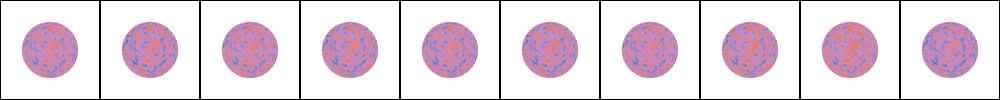

In [7]:
import pyvista as pv

pl = pv.Plotter(shape = (len(ranges),nreps), window_size = (nreps*100, len(ranges)*100))

for ri, ran in ranges:
    for ii in range(nreps):
        pl.subplot(ri,ii)
        pl.add_mesh(sphere_mesh, scalars = instances[ii], cmap = bpr, **mesh_aes)
        pl.camera_position = 'yz'

pl.show(jupyter_backend='static')

In [8]:
Dist = helpers.internal_distance_matrix(v=sphere_mesh.points)

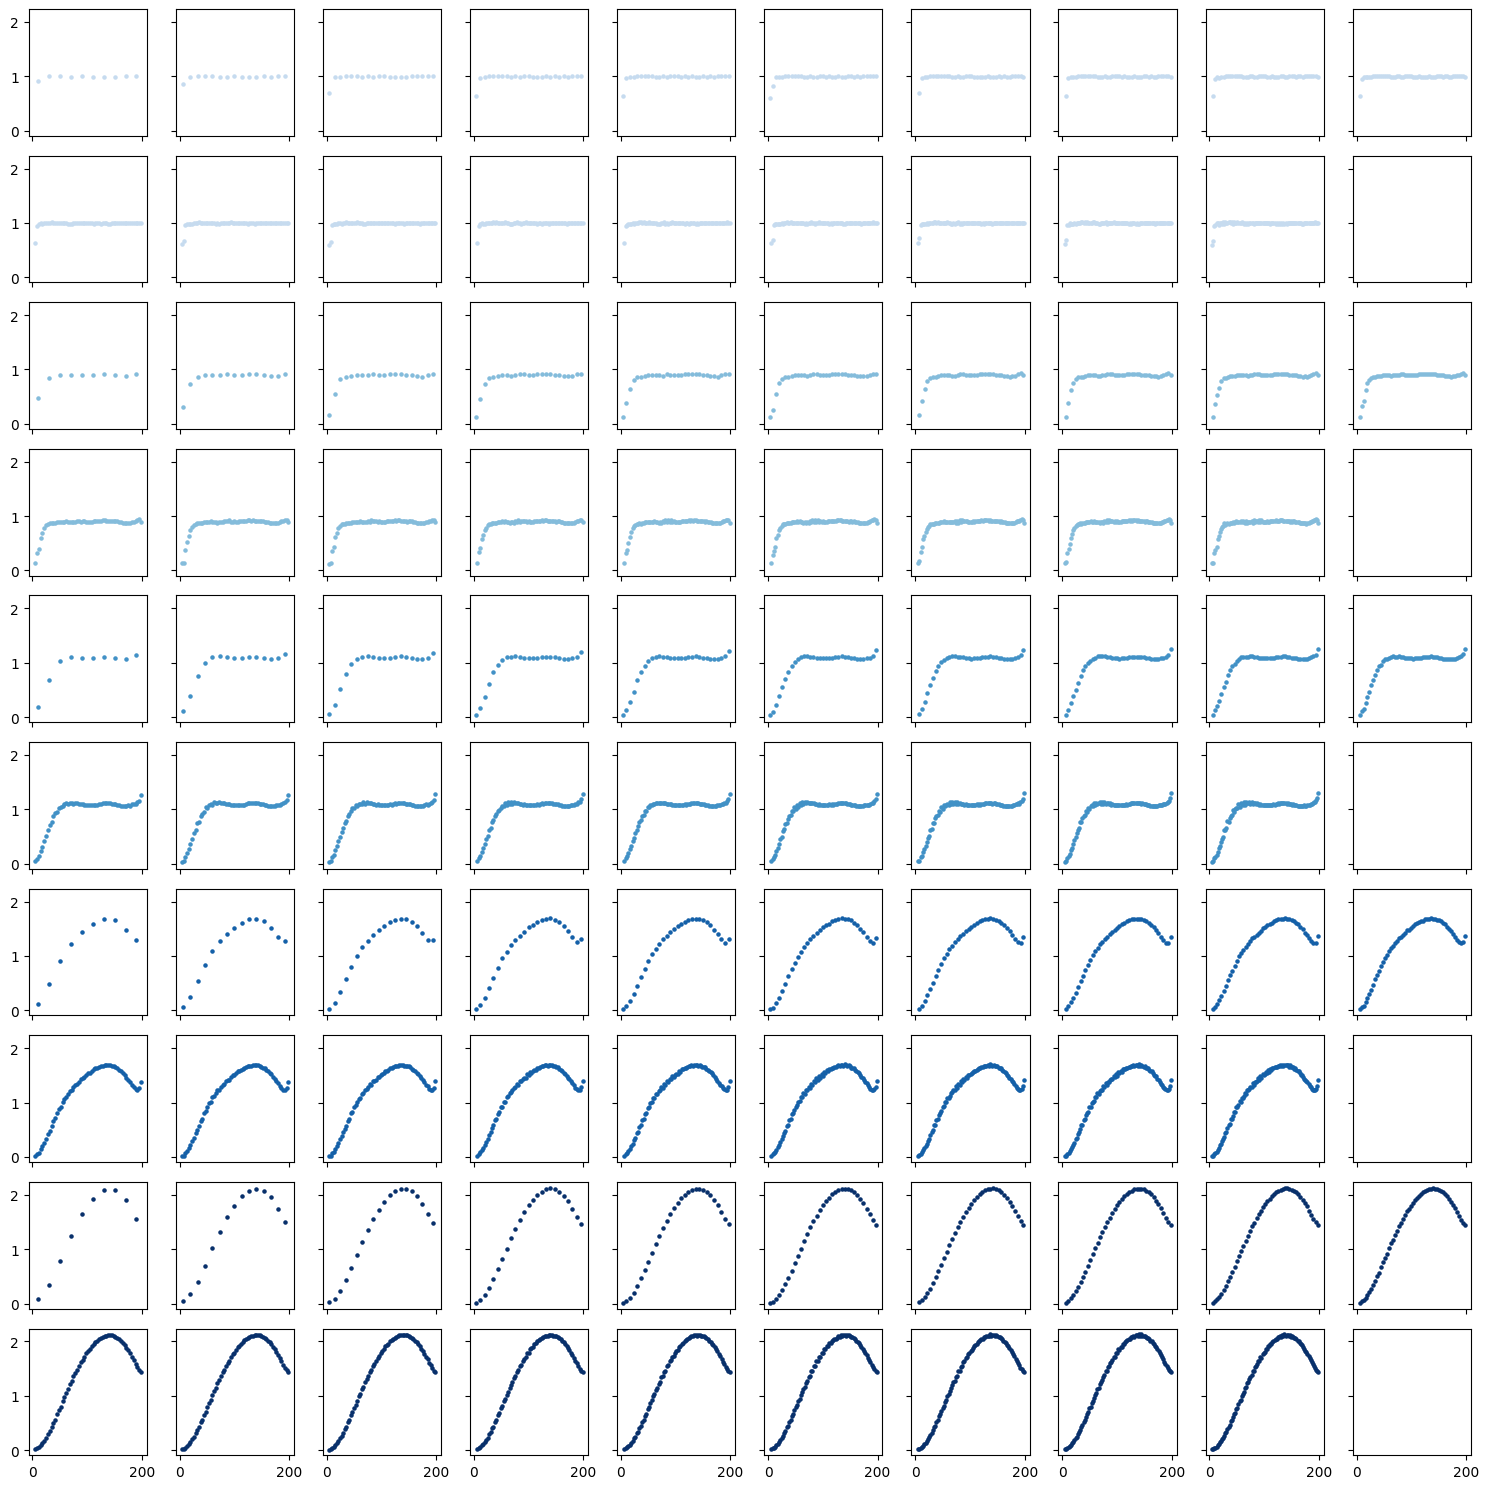

In [120]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2*len(ranges), 10, figsize = (15, 3*len(ranges)), sharex=True, sharey=True)


for ri, ran in enumerate(ranges):

    H = {}
    EV = {}
    NCOUNTS = {}

    instance = helpers.make_random_maps(ran=ran, mesh=sphere_mesh, seed=321)
    
    for ind, nhi in enumerate(NH):
        h, ev, N = helpers.get_empirical_variogram_fast(x=instance,X=sphere_mesh.points,D=Dist,nh=int(nhi),h_bounds='auto', method='euclidean')
        H[nhi] = h
        EV[nhi] = ev
        NCOUNTS[nhi] = N

        row = ri * 2 + ind // 10; col = ind % 10

        axs[row, col].scatter(H[nhi], EV[nhi], color=cmap_discrete(ri / len(ranges)), s=5)


plt.tight_layout()
plt.show()

In [21]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
cmap_cont = plt.cm.Blues

colors = cmap_cont(np.linspace(0.25,1,len(ranges)))
cmap_discrete = ListedColormap(colors)

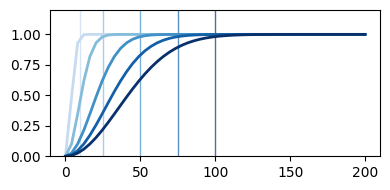

In [23]:
import matplotlib.pyplot as plt
from interpmodules import helpers

plt.figure(figsize = (4,2))


for ri, r in enumerate( ranges ):
    
    x = np.linspace(0,Dist.max())
    
    theoretical = [ helpers.gaussian(h=xi, r=r, c0=1, nugget=0) for xi in x ]

    plt.plot(x, theoretical, color = colors[ri], linewidth=2, zorder = 10)
    plt.axvline(r, color = colors[ri], linewidth = 1, alpha = .7)

plt.ylim([0,1.2])
plt.tight_layout()

# Plotting

In [52]:
ranges = [10, 25, 50, 75, 100]

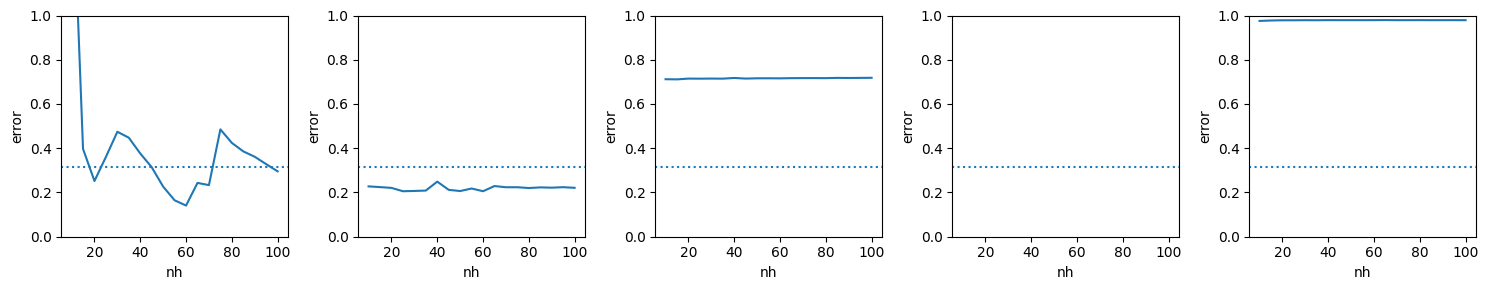

In [109]:
# import spherical mesh
from interpmodules import helpers


nreps = 100


fig, axs = plt.subplots(1, len(ranges), figsize = (15,3))

for ri, ran in enumerate(ranges):


    instances = [ helpers.make_random_maps(ran=ran, mesh=sphere_mesh, seed=i) for i in range(nreps) ]
    
    H = {}
    EV = {}
    NCOUNTS = {}
    
    
    for nhi in NH:
        for ii in range(nreps):
    
            nhi = int(nhi)
            
            h, ev, N = helpers.get_empirical_variogram_fast(x=instances[ii],X=sphere_mesh.points,D=Dist,nh=int(nhi),h_bounds='auto', method='euclidean')
    
            if ii == 0:
                H[nhi] = [h]
                EV[nhi] = [ev]
            else: 
                H[nhi].append(h)
                EV[nhi].append(ev)
                
            NCOUNTS[nhi] = N

    Scores = np.zeros((len(NH), nreps))
    
    for ii in range(nreps):
        scores = np.ones(len(NH))
        
        for ind, nhi in enumerate(NH):
    
            nhi = int(nhi)
            
            x = H[nhi][ii]
            
            theoretical = [ helpers.gaussian(h=xi, r=ran, c0=1, nugget=0) for xi in x ]
        
            if np.isnan(EV[nhi]).any():
                EV[nhi][ii][np.where(np.isnan(EV[nhi][ii]))[0]] = 0
                    
            scores[ind] = root_mean_squared_error(theoretical, EV[nhi][ii]) / np.std(theoretical)
            
        Scores[:,ii] = scores
    
    Scores = pd.DataFrame(Scores.T)
    Scores.columns = NH

    Scores_long = Scores.melt(
    var_name='nh',
    value_name='error'
    )
    
    Scores_long['nh'] = Scores_long['nh'].astype(int)



    sns.lineplot(Scores_long, x='nh', y='error',ax=axs[ri])
    axs[ri].axhline(math.sqrt(.1), linestyle='dotted')
    axs[ri].set_ylim([0,1])

plt.tight_layout()
plt.show()